In [59]:
import pandas as pd
from banco import conectar, executar
import matplotlib.pyplot as plt

In [49]:
# Função para consultar o banco de dados e retornar um DataFrame
def consultar(sql):
    """Executa uma query e retorna DataFrame."""
    conexao = conectar()
    if conexao is None:
        print("Erro ao conectar")
        return None
    
    try:
        df = pd.read_sql(sql, conexao)
        return df
    
    except Exception as e:
        print(f"Erro na query: {e}")
        conexao.close()
        return None
    
    finally:
        conexao.close()

# Função para formatar valores como moeda brasileira
def reais(valor):
    """Formata um número como moeda brasileira."""
    return f"R$ {valor:,.2f}".replace(',', '_').replace('.', ',').replace('_', '.')

Quais os 5 órgãos com maior custo total

In [50]:
# Consulta SQL para obter os 5 órgãos superiores com maior custo total
sql_top_orgaos = """
SELECT
    nome_orgao_superior AS orgao,
    SUM(valor_total) AS custo_total
FROM silver_viagem
WHERE valor_total IS NOT NULL
GROUP BY nome_orgao_superior
ORDER BY custo_total DESC
LIMIT 5;
"""

df_top_orgaos = consultar(sql_top_orgaos)

# Formata a coluna como moeda brasileira
df_top_orgaos["custo_total_formatado"] = (
    df_top_orgaos["custo_total"].apply(reais)
)

display(df_top_orgaos[['orgao', 'custo_total_formatado']])

C:\Users\heloi\AppData\Local\Temp\ipykernel_38412\3756829756.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conexao)


,orgao,custo_total_formatado
0,Ministério da Justiça e Segurança Pública,"R$ 486.933.121,65"
1,Ministério da Defesa,"R$ 156.070.304,49"
2,Ministério da Educação,"R$ 111.291.349,34"
3,Ministério do Meio Ambiente e Mudança do Clima,"R$ 49.697.710,16"
4,Ministério da Previdência Social,"R$ 40.417.309,06"


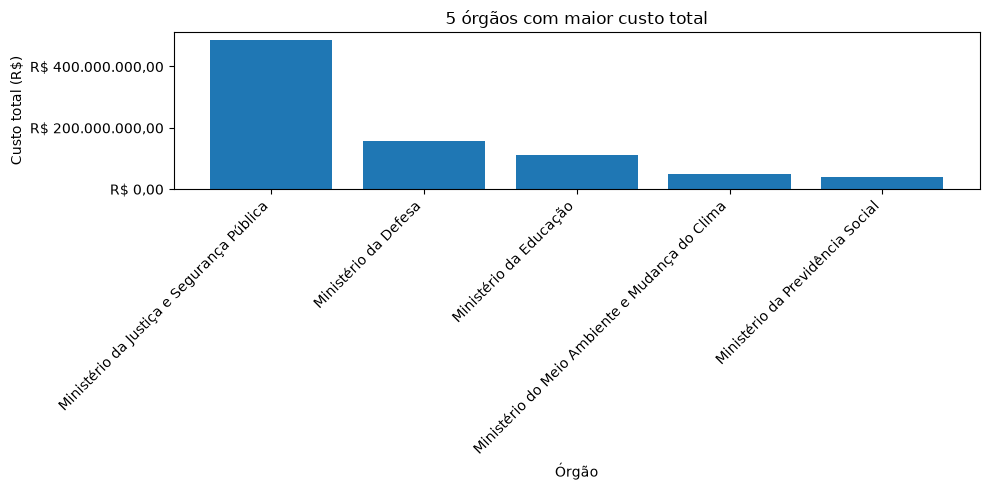

In [53]:
# Gráfico de barras dos 5 órgãos com maior custo total
plt.figure(figsize=(10, 5))

plt.bar(
    df_top_orgaos["orgao"],
    df_top_orgaos["custo_total"]
)

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: reais(x))
)

plt.title("5 órgãos com maior custo total")
plt.xlabel("Órgão")
plt.ylabel("Custo total (R$)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Quais os 3 destinos com maior custo médio por viagem

In [54]:
# Realiza a consulta SQL para obter os 3 destinos com maior custo médio
sql_destino = """
WITH destinos_viagens AS (
    SELECT DISTINCT
        id_viagem,
        destino_cidade
    FROM silver_trecho
    WHERE
        destino_cidade IS NOT NULL
        AND TRIM(destino_cidade) <> ''
)

SELECT
    t.destino_cidade AS destino,
    AVG(v.valor_total) AS custo_medio,
    COUNT(*) AS quantidade_viagens
FROM destinos_viagens t
INNER JOIN silver_viagem v
    ON t.id_viagem = v.id_viagem
WHERE v.valor_total IS NOT NULL
GROUP BY t.destino_cidade
ORDER BY custo_medio DESC
LIMIT 3;
"""

df_top_destinos = consultar(sql_destino)

# Formata a coluna como moeda brasileira
df_top_destinos["custo_medio_formatado"] = (
    df_top_destinos["custo_medio"].apply(reais)

)

display(df_top_destinos[['destino', 'custo_medio_formatado']])

C:\Users\heloi\AppData\Local\Temp\ipykernel_38412\3756829756.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conexao)


,destino,custo_medio_formatado
0,Tejupá,"R$ 115.175,00"
1,Chavantes,"R$ 114.557,01"
2,Teolândia,"R$ 109.322,50"


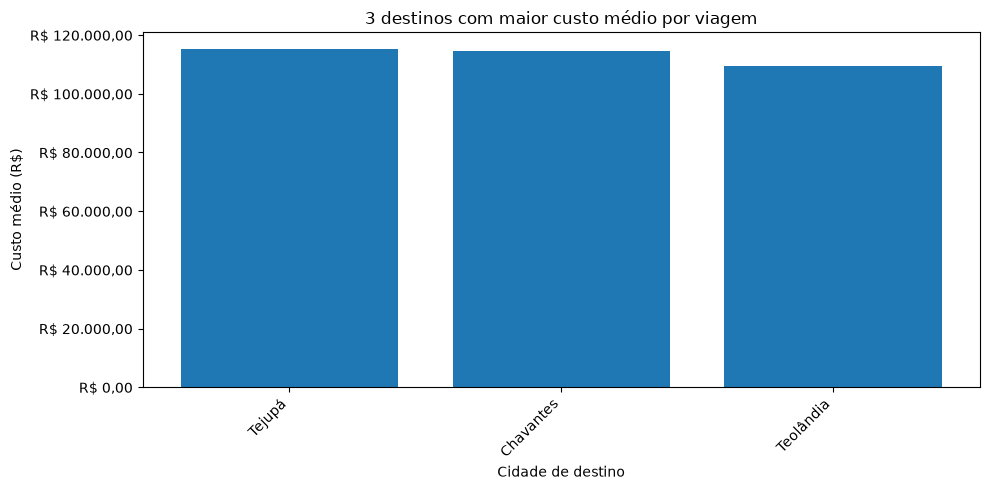

In [55]:
# Gráfico de barras dos 3 destinos com maior custo médio
plt.figure(figsize=(10, 5))

plt.bar(
    df_top_destinos["destino"],
    df_top_destinos["custo_medio"]
)

plt.title("3 destinos com maior custo médio por viagem")
plt.xlabel("Cidade de destino")
plt.ylabel("Custo médio (R$)")

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: reais(x))
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Qual a viagem de maior duração e seu custo total

In [57]:
# Consulta SQL para obter a viagem com maior duração
sql_maior_viagem = """
SELECT
    id_viagem,
    nome_orgao_superior,
    nome_viajante,
    destinos,
    data_inicio,
    data_fim,
    duracao_dias,
    valor_total
FROM silver_viagem
WHERE
    duracao_dias IS NOT NULL
    AND valor_total > 0
ORDER BY duracao_dias DESC
LIMIT 1;
"""

df_maior_viagem = consultar(sql_maior_viagem)

# Formata a coluna como moeda brasileira
df_maior_viagem["valor_total_formatado"] = (
    df_maior_viagem["valor_total"].apply(reais)
)

display(df_maior_viagem)

C:\Users\heloi\AppData\Local\Temp\ipykernel_38412\3756829756.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conexao)


,id_viagem,nome_orgao_superior,nome_viajante,destinos,data_inicio,data_fim,duracao_dias,valor_total,valor_total_formatado
0,0000000000020793594,Ministério da Justiça e Segurança Pública,Informações protegidas por sigilo,Informações protegidas por sigilo,2025-01-02,2026-01-15,378,120650.0,"R$ 120.650,00"


Construção da camada gold

In [58]:
# Criação da VIEW GOLD
sql_view = """
CREATE OR REPLACE VIEW vw_gold_indicadores AS

-- Pergunta 4: Tipo de pagamento com maior valor médio
SELECT
    'valor_medio_pagamento' AS indicador,
    p.tipo_pagamento AS categoria,
    AVG(p.valor) AS valor,
    COUNT(*) AS quantidade
FROM silver_pagamento p
INNER JOIN silver_viagem v
    ON p.id_viagem = v.id_viagem
WHERE
    p.valor IS NOT NULL
    AND p.tipo_pagamento IS NOT NULL
    AND TRIM(p.tipo_pagamento) <> ''
GROUP BY p.tipo_pagamento

UNION ALL

-- Pergunta 5: Meio de transporte mais utilizado
SELECT
    'meio_transporte_mais_usado' AS indicador,
    t.meio_transporte AS categoria,
    COUNT(*)::DECIMAL AS valor,
    COUNT(*) AS quantidade
FROM silver_trecho t
INNER JOIN silver_viagem v
    ON t.id_viagem = v.id_viagem
WHERE
    t.meio_transporte IS NOT NULL
    AND TRIM(t.meio_transporte) <> ''
GROUP BY t.meio_transporte

UNION ALL

-- Pergunta 6: UF de destino mais frequente
SELECT
    'uf_destino_mais_frequente' AS indicador,
    t.destino_uf AS categoria,
    COUNT(*)::DECIMAL AS valor,
    COUNT(*) AS quantidade
FROM silver_trecho t
INNER JOIN silver_viagem v
    ON t.id_viagem = v.id_viagem
WHERE
    t.destino_uf IS NOT NULL
    AND TRIM(t.destino_uf) <> ''
GROUP BY t.destino_uf

UNION ALL

-- Pergunta 7: Órgão que pagou mais no total
SELECT
    'orgao_com_maior_pagamento' AS indicador,
    p.nome_orgao_pagador AS categoria,
    SUM(p.valor) AS valor,
    COUNT(*) AS quantidade
FROM silver_pagamento p
INNER JOIN silver_viagem v
    ON p.id_viagem = v.id_viagem
WHERE
    p.valor IS NOT NULL
    AND p.nome_orgao_pagador IS NOT NULL
    AND TRIM(p.nome_orgao_pagador) <> ''
GROUP BY p.nome_orgao_pagador;
"""

conexao = conectar()

executar(conexao, sql_view)

conexao.close()

print("VIEW GOLD criada com sucesso!")

# Criação da TABELA GOLD
sql_tabela_gold = """
DROP TABLE IF EXISTS gold_indicadores;

CREATE TABLE gold_indicadores AS
SELECT *
FROM vw_gold_indicadores;
"""

conexao = conectar()

executar(conexao, sql_tabela_gold)

conexao.close()

print("Tabela GOLD criada com sucesso!")

VIEW GOLD criada com sucesso!
Tabela GOLD criada com sucesso!


In [35]:
# Consulta SQL para obter os indicadores da tabela GOLD
sql_gold = """
SELECT
    indicador,
    categoria,
    valor,
    quantidade
FROM gold_indicadores
ORDER BY indicador, valor DESC;
"""

df_gold = consultar(sql_gold)

display(df_gold)

C:\Users\heloi\AppData\Local\Temp\ipykernel_38412\3756829756.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conexao)


,indicador,categoria,valor,quantidade
0,meio_transporte_mais_usado,Veículo Oficial,3.864240e+05,386424
1,meio_transporte_mais_usado,Aéreo,2.326660e+05,232666
2,meio_transporte_mais_usado,Rodoviário,6.497000e+04,64970
3,meio_transporte_mais_usado,Veículo Próprio,4.284600e+04,42846
4,meio_transporte_mais_usado,Inválido,2.665900e+04,26659
5,meio_transporte_mais_usado,Fluvial,8.429000e+03,8429
6,meio_transporte_mais_usado,Ferroviário,8.740000e+02,874
7,meio_transporte_mais_usado,Marítimo,4.810000e+02,481
8,orgao_com_maior_pagamento,Fundo Nacional de Segurança Pública,2.784810e+08,79816
9,orgao_com_maior_pagamento,Sigiloso,2.004848e+08,93141


Qual o tipo de pagamento com maior valor médio

In [37]:
# Consulta SQL para obter o tipo de pagamento com maior valor médio
sql_maior_pagamento = """
SELECT
    categoria AS tipo_pagamento,
    valor AS valor_medio,
    quantidade
FROM gold_indicadores
WHERE indicador = 'valor_medio_pagamento'
ORDER BY valor DESC
LIMIT 1;
"""

df_tipo_pagamento = consultar(sql_maior_pagamento)

# Formata o valor médio como moeda brasileira
df_tipo_pagamento["valor_medio_formatado"] = (
    df_tipo_pagamento["valor_medio"].apply(reais)
)

display(df_tipo_pagamento[['tipo_pagamento', 'valor_medio_formatado']])

C:\Users\heloi\AppData\Local\Temp\ipykernel_38412\3756829756.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conexao)


,tipo_pagamento,valor_medio_formatado
0,DIÁRIAS,"R$ 2.078,28"


Qual o meio de transporte mais usado nos trechos

In [38]:
sql_meio_transporte = """
SELECT
    categoria AS meio_transporte,
    quantidade
FROM gold_indicadores
WHERE indicador = 'meio_transporte_mais_usado'
ORDER BY quantidade DESC
LIMIT 1;
"""

df_meio_transporte = consultar(sql_meio_transporte)

display(df_meio_transporte)

C:\Users\heloi\AppData\Local\Temp\ipykernel_38412\3756829756.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conexao)


,meio_transporte,quantidade
0,Veículo Oficial,386424


Qual UF de destino aparece em mais trechos

In [39]:
sql_uf_destino = """
SELECT
    categoria AS uf_destino,
    quantidade
FROM gold_indicadores
WHERE indicador = 'uf_destino_mais_frequente'
ORDER BY quantidade DESC
LIMIT 1;
"""

df_uf_destino = consultar(sql_uf_destino)

display(df_uf_destino)

C:\Users\heloi\AppData\Local\Temp\ipykernel_38412\3756829756.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conexao)


,uf_destino,quantidade
0,São Paulo,82722


Qual órgão pagou mais no total

In [42]:
sql_orgao_pagador = """
SELECT
    categoria AS orgao_pagador,
    valor AS total_pago,
    quantidade
FROM gold_indicadores
WHERE indicador = 'orgao_com_maior_pagamento'
ORDER BY valor DESC
LIMIT 1;
"""

df_orgao_pagador = consultar(sql_orgao_pagador)

# Formata o total pago como moeda brasileira
df_orgao_pagador["total_pago_formatado"] = (
    df_orgao_pagador["total_pago"].apply(reais)
)

display(df_orgao_pagador[['orgao_pagador', 'total_pago_formatado']])

C:\Users\heloi\AppData\Local\Temp\ipykernel_38412\3756829756.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conexao)


,orgao_pagador,total_pago_formatado
0,Fundo Nacional de Segurança Pública,"R$ 278.481.047,89"


Gráfico de valor médio por tipo de pagamento

C:\Users\heloi\AppData\Local\Temp\ipykernel_38412\3756829756.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conexao)


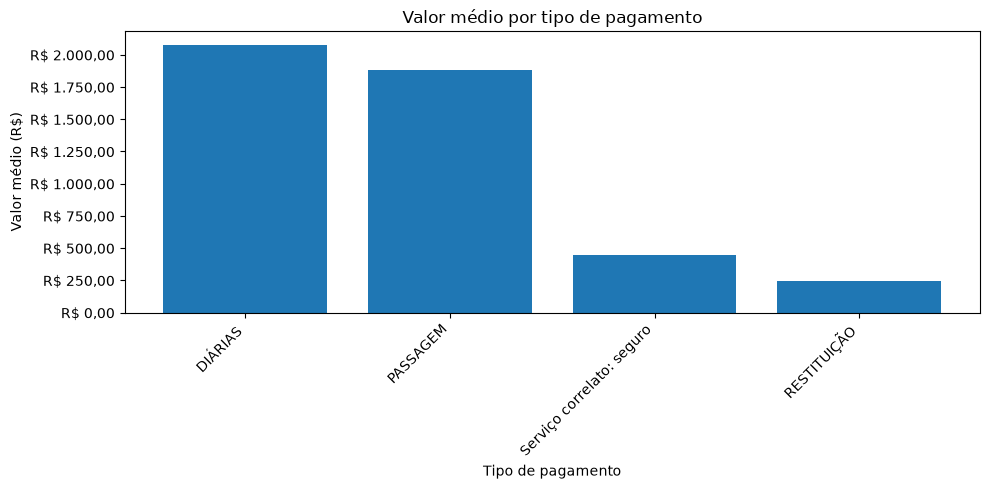

In [43]:
sql_grafico_pagamento = """
SELECT
    categoria AS tipo_pagamento,
    valor AS valor_medio
FROM gold_indicadores
WHERE indicador = 'valor_medio_pagamento'
ORDER BY valor DESC;
"""

df_grafico_pagamento = consultar(sql_grafico_pagamento)

plt.figure(figsize=(10, 5))

plt.bar(
    df_grafico_pagamento["tipo_pagamento"],
    df_grafico_pagamento["valor_medio"]
)

plt.title("Valor médio por tipo de pagamento")
plt.xlabel("Tipo de pagamento")
plt.ylabel("Valor médio (R$)")

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: reais(x))
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Gráfico de meios de transporte mais utilizados

C:\Users\heloi\AppData\Local\Temp\ipykernel_38412\3756829756.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conexao)


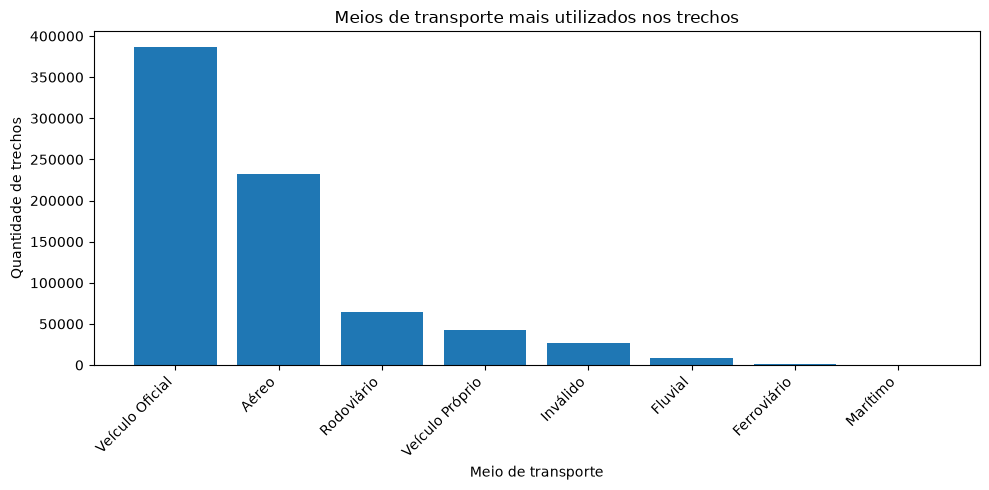

In [45]:
sql_meio_transporte = """
SELECT
    categoria AS meio_transporte,
    quantidade
FROM gold_indicadores
WHERE indicador = 'meio_transporte_mais_usado'
ORDER BY quantidade DESC;
"""

df_grafico_transporte = consultar(sql_meio_transporte)

plt.figure(figsize=(10, 5))

plt.bar(
    df_grafico_transporte["meio_transporte"],
    df_grafico_transporte["quantidade"]
)

plt.title("Meios de transporte mais utilizados nos trechos")
plt.xlabel("Meio de transporte")
plt.ylabel("Quantidade de trechos")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Gráfico das UFs de destino mais frequentes

C:\Users\heloi\AppData\Local\Temp\ipykernel_38412\3756829756.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conexao)


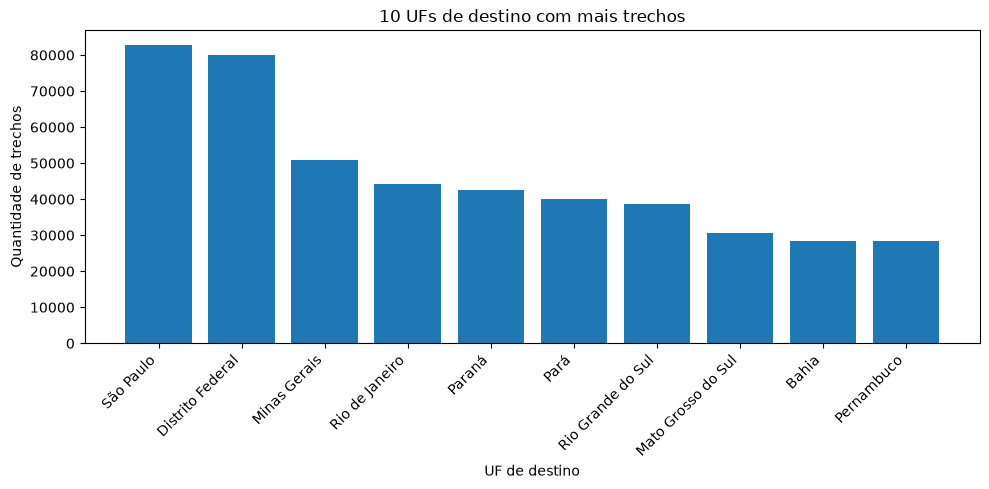

In [60]:
sql_grafico_uf = """
SELECT
    categoria AS uf_destino,
    quantidade
FROM gold_indicadores
WHERE indicador = 'uf_destino_mais_frequente'
ORDER BY quantidade DESC
LIMIT 10;
"""

df_grafico_uf = consultar(sql_grafico_uf)

plt.figure(figsize=(10, 5))

plt.bar(
    df_grafico_uf["uf_destino"],
    df_grafico_uf["quantidade"]
)

plt.title("10 UFs de destino com mais trechos")
plt.xlabel("UF de destino")
plt.ylabel("Quantidade de trechos")

# Rotaciona as legendas do eixo X em 45 graus
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()